In [164]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import statsmodels.api as sm
from statsmodels.formula.api import ols
import math

In [165]:
df = pd.read_excel('DS5_oefendataset_data_cleaning_handling.xlsx',sheet_name='HotelBookings')

df.head()

,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adults,children,stays_in_week_nights,meal,country,customer_type,is_canceled,price_per_night,market_segment,reservation_status
0,20001,Resort Hotel,2026,November,7,2.0,2.0,6,FB,NLD,Transient,1,66.27,Corporate,Check-Out
1,20002,Resort Hotel,2025,July,1,3.0,2.0,3,FB,BEL,Transient,0,199.34,Online TA,Check-Out
2,20003,Resort Hotel,2026,June,18,4.0,2.0,8,HB,GBR,Contract,0,100.38,Direct,Check-Out
3,20004,Resort Hotel,2024,january,8,1.0,1.0,9,FB,FRA,Group,0,223.69,Direct,Canceled
4,20005,Resort Hotel,2025,July,7,2.0,0.0,9,FB,ESP,Contract,0,172.56,Corporate,Canceled


In [166]:
df2 = df.copy


In [167]:
# bookin id 
df['booking_id'].duplicated().any()
df = df.drop_duplicates(subset = 'booking_id')
df['booking_id'].duplicated().any()

np.False_

In [168]:
#arrival?date?year
df['arrival_date_year'].unique()
df = df[df['arrival_date_year'] != 2099]
df['arrival_date_year'].unique()

array([2026, 2025, 2024])

In [169]:
# arrival date month
df['arrival_date_month'].unique()
df['arrival_date_month'] = df['arrival_date_month'].astype(str)
df['arrival_date_month'] = df['arrival_date_month'].str.capitalize()
df['arrival_date_month'].unique()

array(['November', 'July', 'June', ' january ', 'January', 'March', 'May',
       'December', 'September', 'April', 'October', 'February', 'August',
       'Nan'], dtype=object)

In [170]:
#drop nan 
df.isna().sum()
df = df.dropna(subset = ['adults', 'children', 'country', 'price_per_night'])
df.head()

,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adults,children,stays_in_week_nights,meal,country,customer_type,is_canceled,price_per_night,market_segment,reservation_status
0,20001,Resort Hotel,2026,November,7,2.0,2.0,6,FB,NLD,Transient,1,66.27,Corporate,Check-Out
1,20002,Resort Hotel,2025,July,1,3.0,2.0,3,FB,BEL,Transient,0,199.34,Online TA,Check-Out
2,20003,Resort Hotel,2026,June,18,4.0,2.0,8,HB,GBR,Contract,0,100.38,Direct,Check-Out
3,20004,Resort Hotel,2024,january,8,1.0,1.0,9,FB,FRA,Group,0,223.69,Direct,Canceled
4,20005,Resort Hotel,2025,July,7,2.0,0.0,9,FB,ESP,Contract,0,172.56,Corporate,Canceled


In [171]:
#arrival_date_day_of_month
df['arrival_date_day_of_month'].unique()
df = df[df['arrival_date_day_of_month'] >1] 
df = df[df['arrival_date_day_of_month'] <= 31]
df['arrival_date_day_of_month'].unique()


array([ 7, 18,  8,  4,  3, 24,  2,  6, 12,  5, 25,  9, 23, 13, 20, 28, 11,
       21, 15, 16, 14, 19, 27, 22, 26, 17, 10])

In [172]:
# adults 
print(df['adults'].unique())
df['adults'] = df['adults'].astype('int64')
df['adults'] = df['adults'].astype('int64')
df = df[df['adults'] != 3500]

df.head()

[2.0e+00 4.0e+00 1.0e+00 3.0e+00 3.5e+03]


,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adults,children,stays_in_week_nights,meal,country,customer_type,is_canceled,price_per_night,market_segment,reservation_status
0,20001,Resort Hotel,2026,November,7,2,2.0,6,FB,NLD,Transient,1,66.27,Corporate,Check-Out
2,20003,Resort Hotel,2026,June,18,4,2.0,8,HB,GBR,Contract,0,100.38,Direct,Check-Out
3,20004,Resort Hotel,2024,january,8,1,1.0,9,FB,FRA,Group,0,223.69,Direct,Canceled
4,20005,Resort Hotel,2025,July,7,2,0.0,9,FB,ESP,Contract,0,172.56,Corporate,Canceled
5,20006,Resort Hotel,2026,January,4,4,1.0,2,HB,BEL,Group,0,230.57,Direct,Canceled


In [173]:
# children
df['children'].unique()
df = df[df['children'] != 200]
df['children'] = df['children'].astype('int64')
df['children'].unique()

array([2, 1, 0])

In [ ]:
#stays in week nights
df['stays_in_week_nights'].unique()
df = df[df['stays_in_week_nights'] >0]

In [184]:
#meal
df['meal'].unique()
df['meal'] = df['meal'].str.upper()
df['meal'].unique()
df.head()

,booking_id,hotel,arrival_date_year,arrival_date_month,arrival_date_day_of_month,adults,children,stays_in_week_nights,meal,country,customer_type,is_canceled,price_per_night,market_segment,reservation_status
0,20001,Resort Hotel,2026,November,7,2,2,6,FB,NLD,Transient,1,66.27,Corporate,Check-Out
2,20003,Resort Hotel,2026,June,18,4,2,8,HB,GBR,Contract,0,100.38,Direct,Check-Out
3,20004,Resort Hotel,2024,january,8,1,1,9,FB,FRA,Group,0,223.69,Direct,Canceled
4,20005,Resort Hotel,2025,July,7,2,0,9,FB,ESP,Contract,0,172.56,Corporate,Canceled
5,20006,Resort Hotel,2026,January,4,4,1,2,HB,BEL,Group,0,230.57,Direct,Canceled


In [ ]:
# country
df['country'].unique()
df = df[df['country']!= 3] 
df['country'].unique()

array(['NLD', 'GBR', 'FRA', 'ESP', 'BEL', 'DEU', ' NLD '], dtype=object)

In [195]:
# customer_type
df['customer_type'].unique()
df['customer_type'] = df['customer_type'].str.strip()
df['customer_type'] = df['customer_type'].str.capitalize()
df['customer_type'] = df['customer_type'].replace('G  roup', 'Group')
df['customer_type'].unique()


array(['Transient', 'Contract', 'Group'], dtype=object)

In [207]:
# is _canceled
df['is_canceled'].value_counts()
df['is_canceled'] = df['is_canceled'].replace('yes', 1)
df['is_canceled'].unique()

array([1, 0])

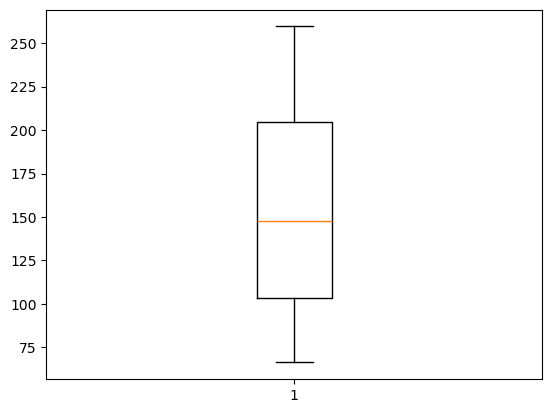

In [ ]:
# price_per_night
df['price_per_night'].unique()
df = df[df['price_per_night'] != 'unknown']
df = df[df['price_per_night'] > 0]
df['price_per_night'].unique()
plt.boxplot(df['price_per_night']);

In [218]:
#market_segment
df['market_segment'].unique()

array(['Corporate', 'Direct', 'Online TA'], dtype=object)

In [221]:
#reservation_status
df['reservation_status'].unique()
df['reservation_status'] = df['reservation_status'].replace('cancelled', 'Canceled')
df['reservation_status'].unique()

array(['Check-Out', 'Canceled'], dtype=object)